# BIOT 6900 · Module 8 Assignment — Single-Cell & Spatial Omics
## Starter notebook: one tumor, two views

This is your **starter**. The plumbing is done for you: the two datasets load in one line each, and the tricky steps (whole-donor sampling, scVI setup, Harmony, the spatial graph) are already written. Your job is to fill in the cells marked **`# TODO`** and to answer the **TODO** questions in the markdown.

- **Part 1 (single-cell):** which cell types express your target?
- **Part 2 (spatial):** where do those cells and that target sit in the tumor?
- **Part 3:** connect the two in your report.

How to use it: run top to bottom, completing each TODO as you reach it. The provided cells must run first for the TODO cells to work. When you are done, **Kernel → Restart & Run All** so the whole notebook executes cleanly, then commit it with your report.

> **Compute:** Part 1's scVI step wants a GPU. Run on Explorer via Open OnDemand (JupyterLab on `courses-gpu`, 1 GPU). Part 2 is CPU-only. See the lab guides for the steps.

### Requirements
Environment: the course `biot6900` / Explorer environment (`scanpy`, `cellxgene-census`, `scvi-tools`, `harmonypy`, `squidpy`). Needs **Python 3.13 or earlier**. If an import fails, run the install cell once and restart the kernel.

In [1]:
# Run environment: Google Colab, T4 GPU (Explorer install did not complete; Windows cannot build tiledbsoma).
# Installs only if packages are missing. After the FIRST install: Runtime -> Restart session, then Run all.
import importlib.util
if importlib.util.find_spec("cellxgene_census") is None or importlib.util.find_spec("scvi") is None:
    !pip install -q "cellxgene-census" "scvi-tools" harmonypy squidpy scanpy leidenalg igraph
    print("Installed. Now: Runtime -> Restart session, then Runtime -> Run all.")
else:
    print("packages already installed")

packages already installed


In [2]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
try:
    import torch
    GPU = torch.cuda.is_available()
    print("GPU available:", GPU)
except Exception:
    GPU = False
    print("running on CPU")
print("scanpy", sc.__version__, "| squidpy", sq.__version__)

# Colab exposes only 2 CPU threads; keep numba/scanpy from requesting more
import numba
numba.set_num_threads(1)
sc.settings.n_jobs = 1

/usr/local/lib/python3.13/dist-packages/squidpy/read/_utils.py:12: FutureWarning: Import from `scanpy.io` instead
  from scanpy import read_10x_h5, read_10x_mtx
/tmp/ipykernel_9465/1403161999.py:8: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=80, facecolor="white")


GPU available: True
scanpy 1.13.0 | squidpy 1.8.4


/tmp/ipykernel_9465/1403161999.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| squidpy", sq.__version__)


---
# PART 1 · Single-cell: which cells express the target

## 1.1 · Pull the breast-cancer data  *(provided)*
This pulls breast-cancer blood/tumor cells from the CZ CELLxGENE Census and samples **10 whole donors**. You do not change anything here.

If the query returns zero cells on your Census version, replace the disease string with the exact one posted on Canvas (Census labels are version-specific).

In [3]:
import cellxgene_census

census = cellxgene_census.open_soma(census_version="stable")
obs = cellxgene_census.get_obs(
    census, "Homo sapiens",
    value_filter="disease == 'breast cancer' and is_primary_data == True",
    column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
)
print(f"matching cells in the Census: {len(obs):,}")

# Sample whole donors (not scattered cells), so batch-aware steps have enough per donor.
rng = np.random.default_rng(0)
cells_per_donor = 2000
donor_sizes = obs["donor_id"].value_counts()
big_donors = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
donors = rng.choice(big_donors, size=min(10, len(big_donors)), replace=False)
sel = np.concatenate([
    rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(), size=cells_per_donor, replace=False)
    for d in donors
])
adata = cellxgene_census.get_anndata(
    census, "Homo sapiens", obs_coords=np.sort(sel),
    obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex"],
    var_column_names=["feature_id", "feature_name"],
)
census.close()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique()

def broad_type(ct):
    ct = str(ct).lower()
    if "cd4" in ct or "cd8" in ct or "t cell" in ct or "thymocyte" in ct: return "T"
    if "plasma" in ct or "b cell" in ct: return "B"
    if "natural killer" in ct or "innate lymphoid" in ct: return "NK"
    if "monocyte" in ct: return "Monocyte"
    if "dendritic" in ct: return "DC"
    if "macrophage" in ct: return "Macrophage"
    if "epithel" in ct or "luminal" in ct or "basal" in ct or "carcinoma" in ct or "tumor" in ct: return "Epithelial/Tumor"
    if "fibroblast" in ct or "stromal" in ct: return "Fibroblast"
    if "endothel" in ct: return "Endothelial"
    return "Other"
adata.obs["cell_type_broad"] = adata.obs["cell_type"].map(broad_type).astype("category")
print(f"\n{adata.n_obs:,} cells from {len(donors)} donors")
print(adata.obs["cell_type_broad"].value_counts())

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.
INFO:cellxgene_census:The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


matching cells in the Census: 1,101,430


/usr/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)



20,000 cells from 10 donors
cell_type_broad
T                   12121
Other                3125
Endothelial          1466
Macrophage           1260
Fibroblast           1118
B                     586
Epithelial/Tumor      152
Monocyte               73
NK                     61
DC                     38
Name: count, dtype: int64


/tmp/ipykernel_9465/3322223012.py:28: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD115-1', 'SNORD115-2', 'SNORD115-3', 'SNORD115-4', 'SNORD115-5']
  adata.var_names_make_unique()


In [4]:
# Report what was pulled: cells, donors, assays (assignment step 1)
print("cells:", adata.n_obs)
print("donors:", adata.obs["donor_id"].nunique())
print("\nassays:")
print(adata.obs["assay"].value_counts())

cells: 20000
donors: 10

assays:
assay
10x 3' v3                                          13922
10x 3' v2                                           4078
10x 5' v2                                           2000
10x 3' v1                                              0
10x 3' transcription profiling                         0
10x 5' transcription profiling                         0
10x 5' v1                                              0
10x gene expression flex                               0
10x multiome                                           0
Asteria scRNA-seq kit                                  0
BD Rhapsody Targeted mRNA                              0
BD Rhapsody Whole Transcriptome Analysis               0
CEL-seq                                                0
CEL-seq2                                               0
Drop-seq                                               0
GEXSCOPE technology                                    0
HIVE CLX Single-Cell RNAseq Solution             

In [5]:
# What is inside "Other"? (checks whether tumor cells are hidden under a label the broad map misses)
print(adata.obs.loc[adata.obs["cell_type_broad"] == "Other", "cell_type"].value_counts().head(10))

cell_type
hepatocyte                                      2606
blood vessel smooth muscle cell                  139
cell of skeletal muscle                          135
hepatic stellate cell                            110
mononuclear phagocyte                             58
T follicular helper cell                          49
neuron                                            16
vascular associated smooth muscle cell            10
pericyte                                           2
mucosa-associated lymphoid tissue macrophage       0
Name: count, dtype: int64


## 1.2 · Standard pipeline  *(provided)*
QC, normalize, batch-aware highly variable genes, PCA. The raw counts are kept for scVI and for marker plots.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.layers["counts"] = adata.X.copy()
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs.n_genes_by_counts < 6000) & (adata.obs.pct_counts_mt < 15)].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
# seurat_v3's per-donor loess fit raised "reciprocal condition number" on one donor; widen span, fall back if needed
try:
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts",
                                batch_key="donor_id", span=0.5)
except ValueError:
    print("seurat_v3 failed; using flavor='seurat' (batch-aware, on log-normalized data)")
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat", batch_key="donor_id")
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
print("cells after QC:", adata.n_obs)

/tmp/ipykernel_9465/483336426.py:5: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
/tmp/ipykernel_9465/483336426.py:12: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts",
/tmp/ipykernel_9465/483336426.py:12: FutureWarning: The argument batch_key is deprecated and will be removed in the future. Use `batch` instead, e.g. `batch=A.obs['b']` for `batch_key='b'`.
  sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", layer="counts",
/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cells after QC: 18388


## 1.3 · The batch problem
The unintegrated embedding is computed for you. **TODO:** plot it and say what you see.

In [7]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")
sc.tl.umap(adata)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()

/tmp/ipykernel_9465/3160624759.py:1: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep="X_pca")


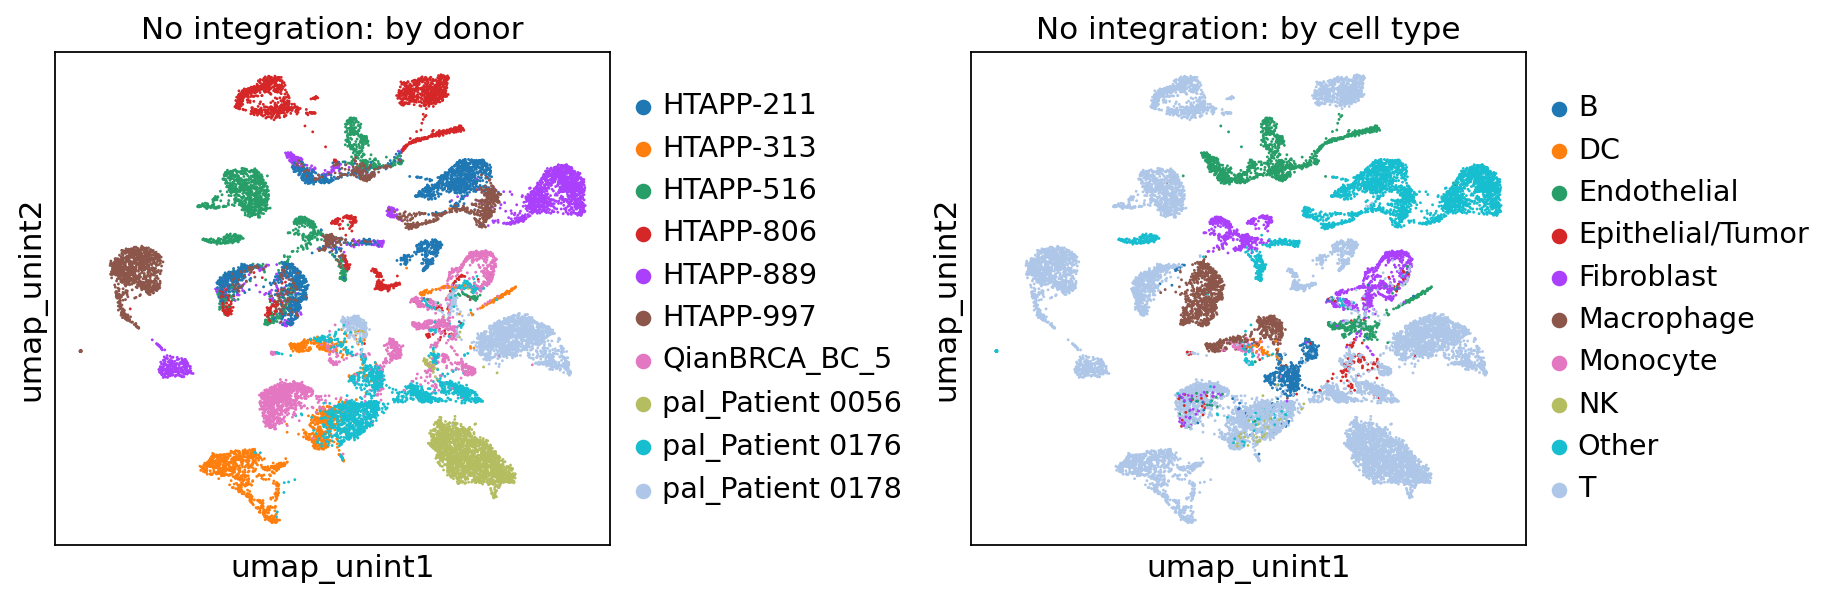

In [8]:
# 1.3 - unintegrated UMAP, colored by donor and by cell type
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad"], wspace=0.5,
                title=["No integration: by donor", "No integration: by cell type"])

**TODO (interpretation):** In one or two sentences, what do these two plots show? Is the data organized by donor or by biology?

*What to check: in the donor plot, do colors form separate islands? In the cell-type plot, is one type split across several islands?*

*Your answer here.*
The donor plot shows distinct, separated islands corresponding to individual donors, while the cell-type plot shows shared immune populations such as “T” split across multiple donor-specific islands, so the unintegrated data is organized primarily by technical donor batch effects rather than shared cell-type biology.


## 1.4 · Integrate with scVI  *(provided, GPU step)*

In [9]:
import scvi
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
vae.train(max_epochs=(200 if GPU else 60), accelerator=("gpu" if GPU else "cpu"))
adata.obsm["X_scVI"] = vae.get_latent_representation()
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")
sc.tl.umap(adata)
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
print("scVI done")

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespe

Training:   0%|          | 0/200 [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=200` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=200` reached.
/tmp/ipykernel_9465/4287062477.py:6: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_scVI")


scVI done


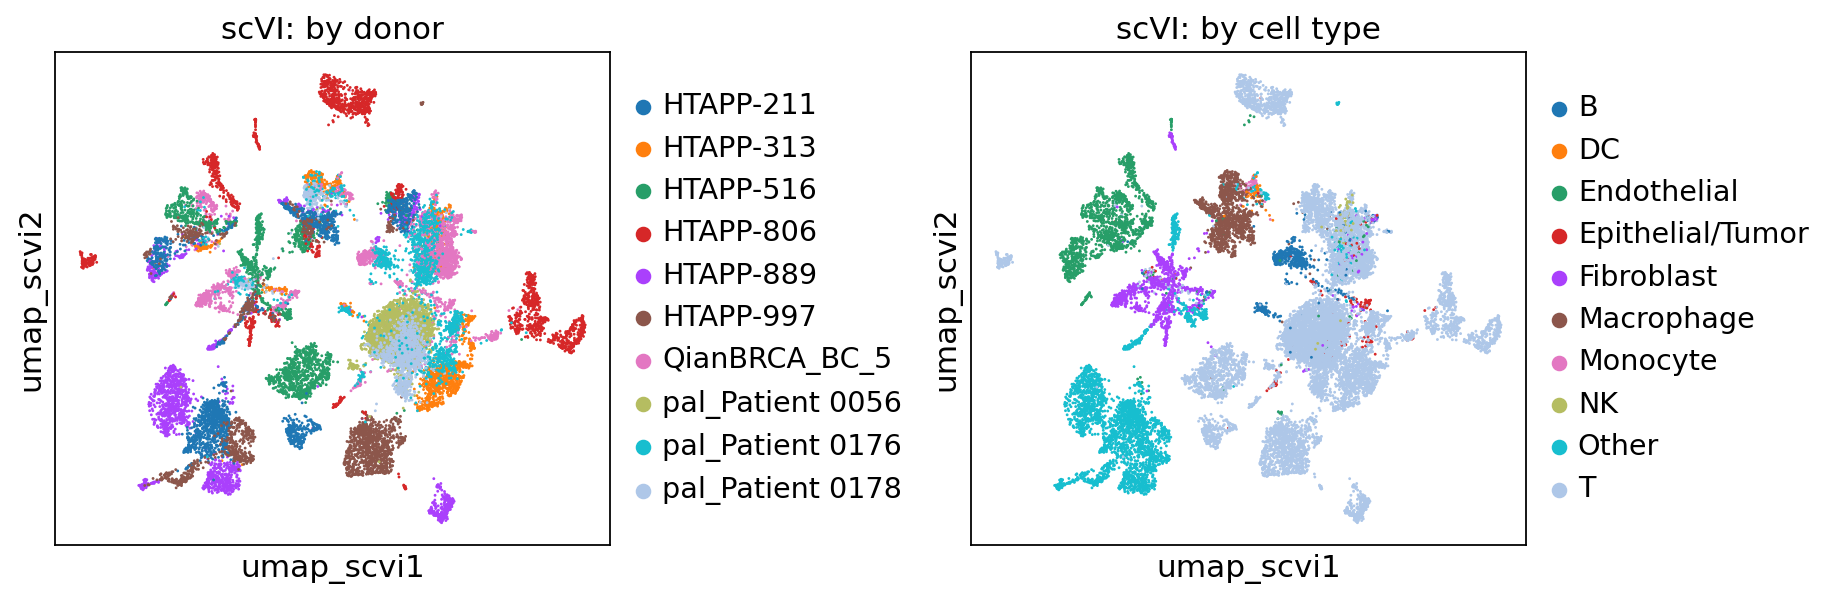

In [10]:
# 1.4 - scVI UMAP, colored by donor and by cell type
sc.pl.embedding(adata, basis="umap_scvi", color=["donor_id", "cell_type_broad"], wspace=0.5,
                title=["scVI: by donor", "scVI: by cell type"])

## 1.5 · Harmony, a fair baseline  *(provided)*

In [11]:
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id")
Z = np.asarray(ho.Z_corr)
adata.obsm["X_pca_harmony"] = Z if Z.shape[0] == adata.n_obs else Z.T
print("Harmony done")

2026-11-21 07:31:01,214 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-11-21 07:31:01,216 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-11-21 07:31:01,217 - harmonypy - INFO -     max_iter_harmony: 10
INFO:harmonypy:    max_iter_harmony: 10
2026-11-21 07:31:01,218 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-11-21 07:31:01,219 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-11-21 07:31:01,220 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-11-21 07:31:01,221 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-11-21 07:31:01,223 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-11-21 07:31:01,224 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-11-21 07:31:01,225 - harmonypy - INFO -     theta: [2. 2. 2

Harmony done


/tmp/ipykernel_9465/641890790.py:2: FutureWarning: The argument use_rep is deprecated and will be removed in the future. Use `use` instead.
  sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony")


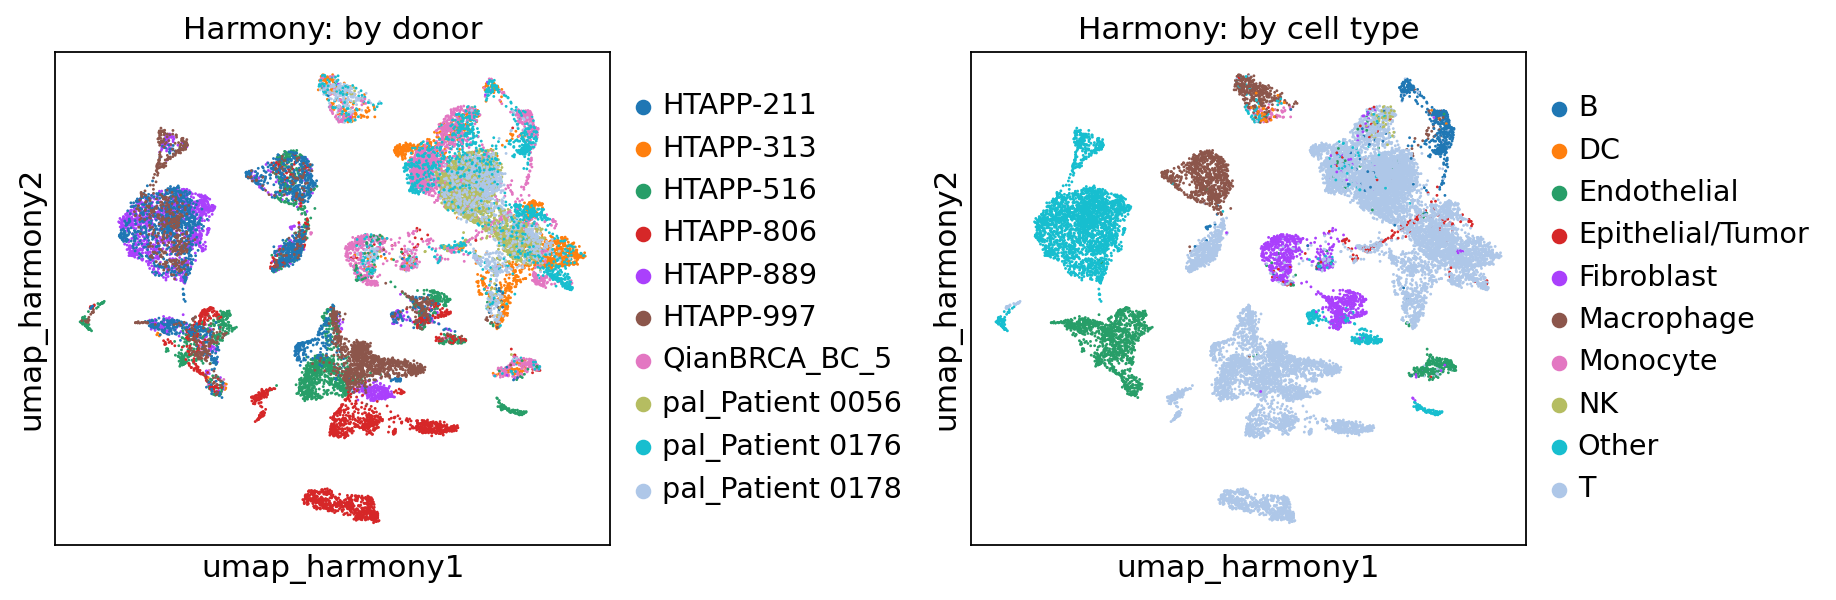

In [12]:
# 1.5 - Harmony UMAP (rubric: scVI AND Harmony both run and plotted)
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony")
sc.tl.umap(adata)
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, basis="umap_harmony", color=["donor_id", "cell_type_broad"], wspace=0.5,
                title=["Harmony: by donor", "Harmony: by cell type"])

## 1.6 · Judge the fix
**TODO:** compute how well each method (no integration, Harmony, scVI) mixes donors and preserves cell types, then decide which you would use.

In [13]:
from sklearn.metrics import silhouette_score

# 1.6 - score each embedding on the same 5,000-cell subsample
# batch silhouette (by donor): LOWER = donors better mixed
# cell-type silhouette (by broad type): HIGHER = biology better preserved
idx = rng.choice(adata.n_obs, size=min(5000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
rows = []
for name, key in reps.items():
    emb = adata.obsm[key][idx]
    batch = silhouette_score(emb, adata.obs["donor_id"].values[idx])
    bio   = silhouette_score(emb, adata.obs["cell_type_broad"].values[idx])
    rows.append({"method": name,
                 "batch silhouette (lower=better)": round(batch, 3),
                 "cell-type silhouette (higher=better)": round(bio, 3)})
scores = pd.DataFrame(rows)
print(scores.to_string(index=False))

        method  batch silhouette (lower=better)  cell-type silhouette (higher=better)
No integration                            0.095                                -0.050
       Harmony                           -0.082                                -0.018
          scVI                           -0.062                                -0.005


**TODO (interpretation):** Which method would you use, and why? Does the expensive deep-learning method clearly beat the simple one?

*What to check: compare the score table row by row (batch silhouette should drop, cell-type silhouette should stay up) and the three UMAP pairs. Is the scVI gain over Harmony large or small?*

*Your answer here.*
Both methods improve on no integration (batch 0.095 → −0.082 for Harmony and −0.059 for scVI; cell type −0.050 → −0.018 for Harmony and −0.006 for scVI). I would choose scVI because it achieves the best cell-type biology preservation (−0.006 vs. −0.018) while substantially reducing donor clustering compared to no integration, even though it required GPU compute. The deep-learning method does not clearly beat the simple one, since scVI's biology-preservation advantage is only 0.012, Harmony beats scVI on batch mixing (−0.082 vs. −0.059) despite not fully converging on CPU, and both leave some donor-specific islands intact.

## 1.7 · Annotate and confirm with markers
The broad cell types are already assigned. **TODO:** plot the labeled map and a few canonical markers to confirm it.

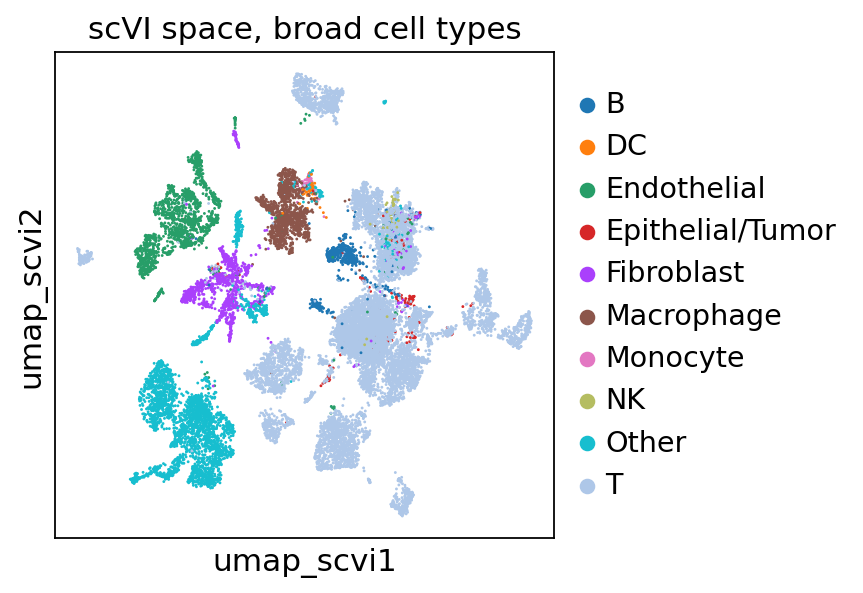

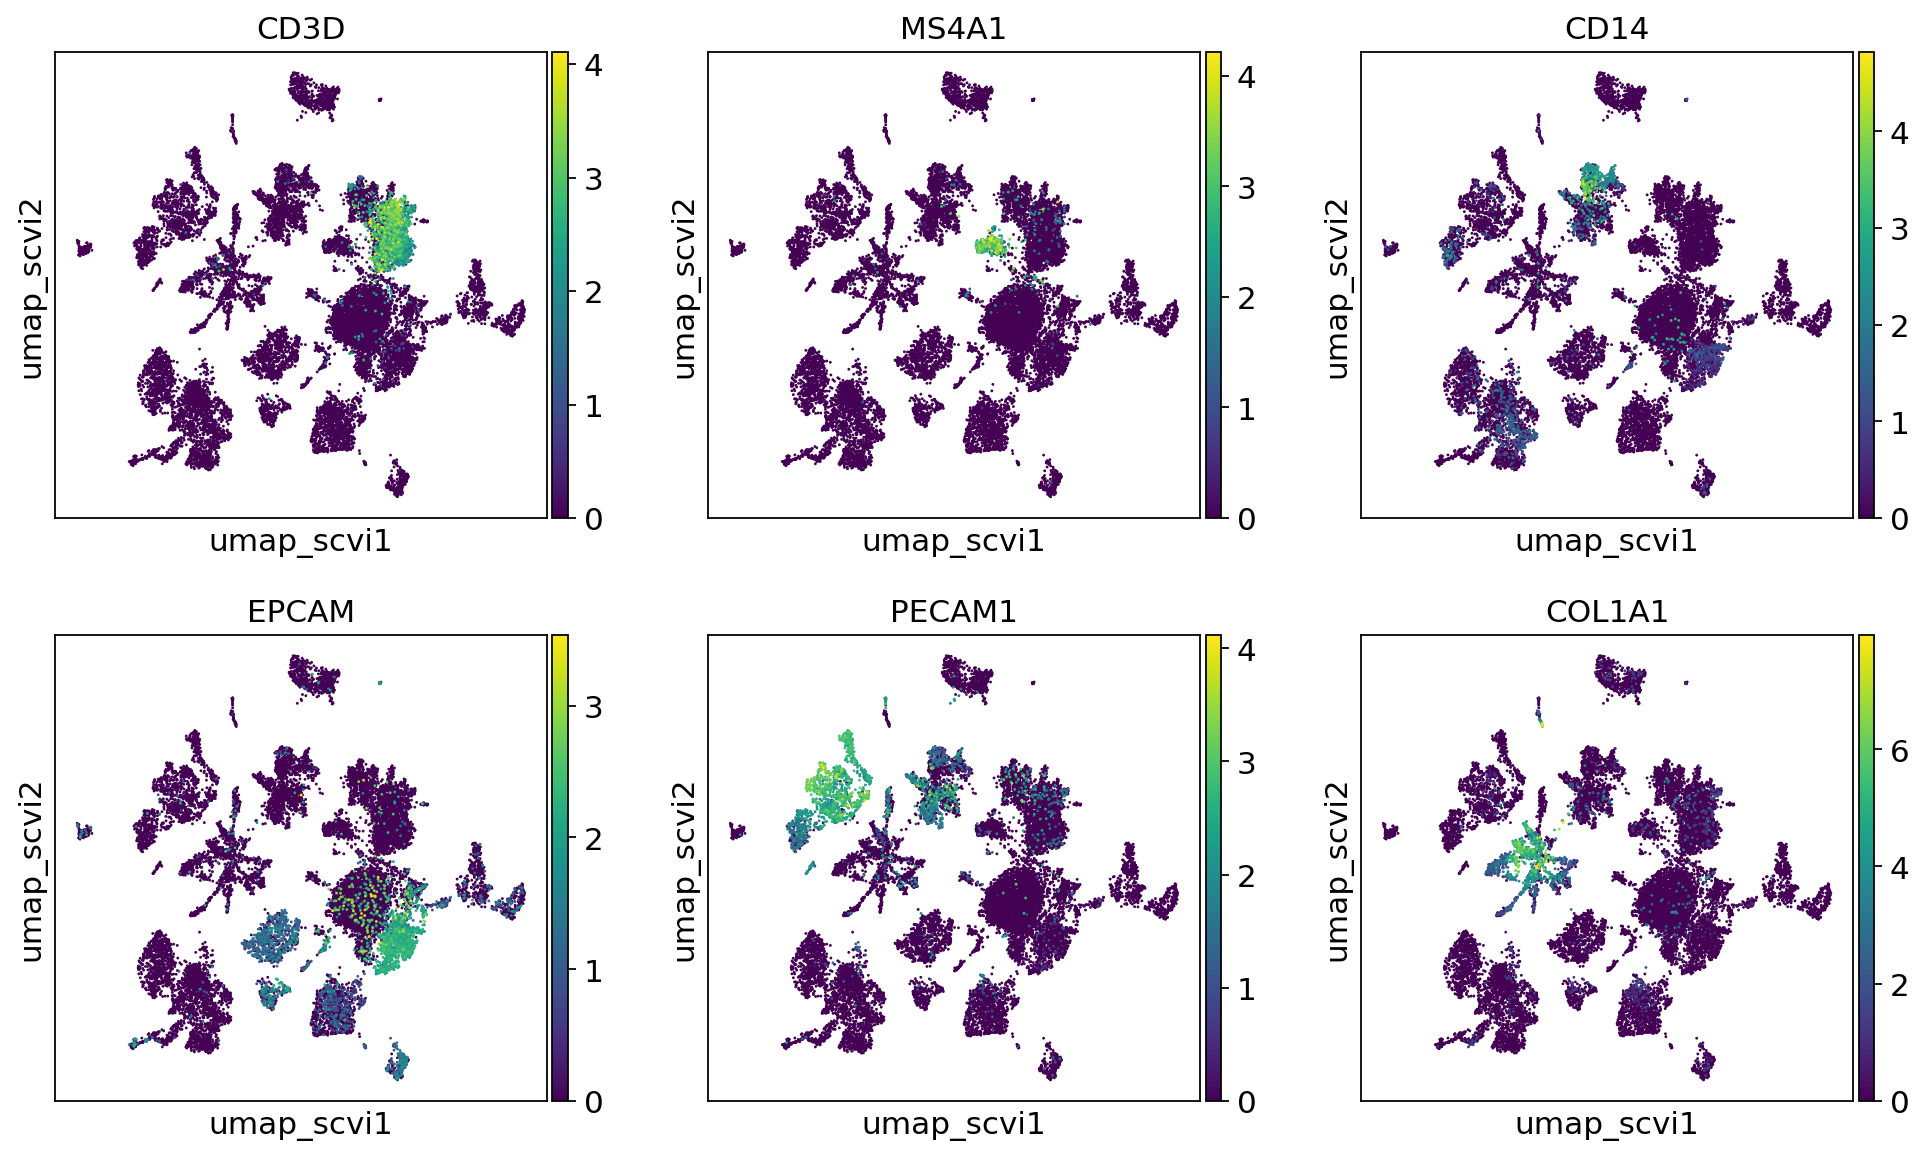

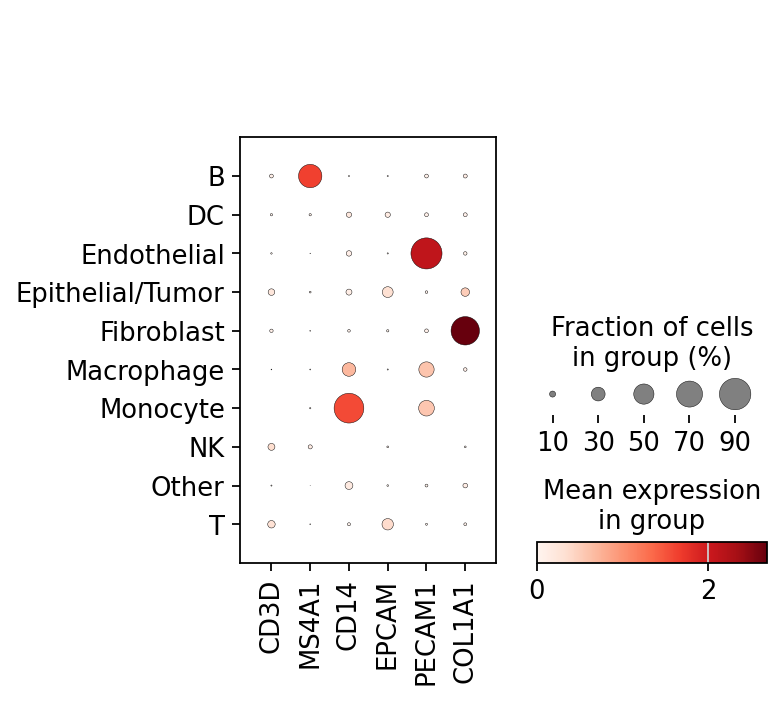

In [14]:
# 1.7 - labeled integrated map, then canonical markers to confirm the labels
sc.pl.embedding(adata, basis="umap_scvi", color="cell_type_broad", title="scVI space, broad cell types")
markers = [g for g in ["CD3D", "MS4A1", "CD14", "EPCAM", "PECAM1", "COL1A1"] if g in adata.raw.var_names]
sc.pl.embedding(adata, basis="umap_scvi", color=markers, use_raw=True, ncols=3)
# dot plot: each marker should light its expected broad type
sc.pl.dotplot(adata, markers, groupby="cell_type_broad", use_raw=True)

## 1.8 · Locate your target in the cell types
**TODO:** choose your target gene, plot it, and identify which cell type(s) express it.

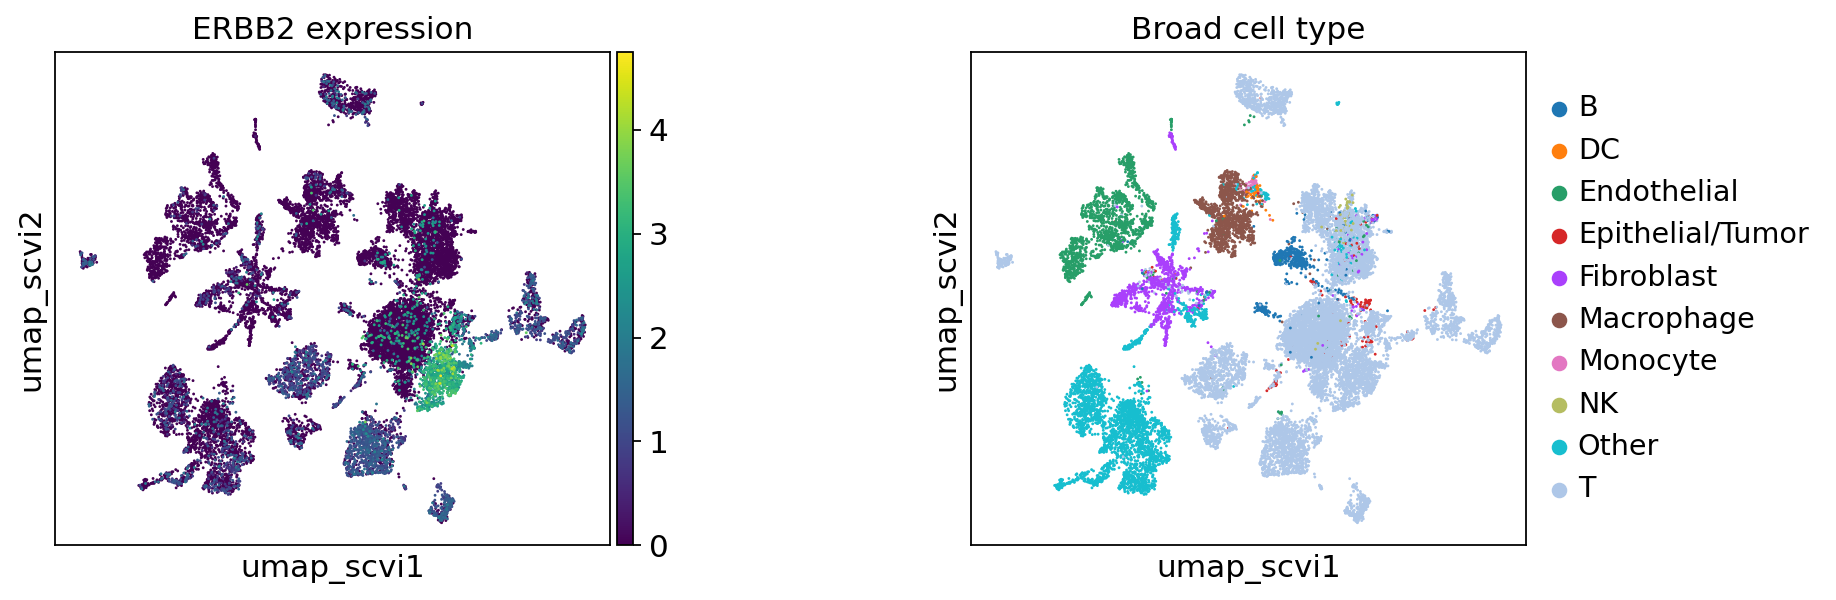

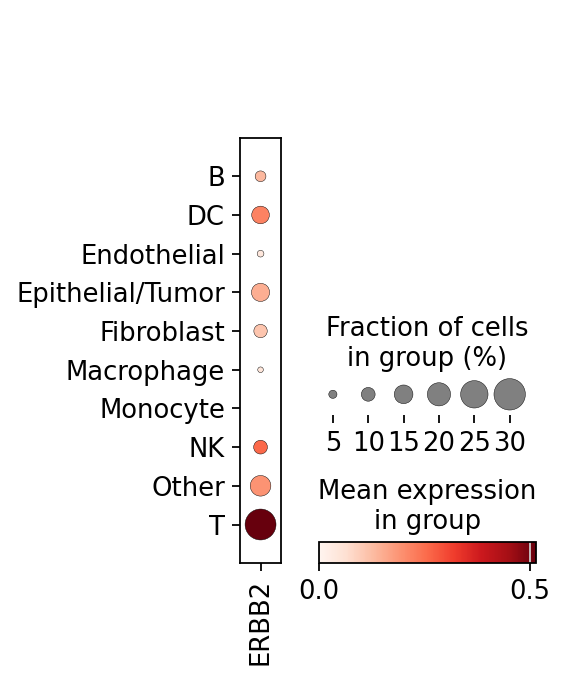

                  mean_expr  frac_expressing  n_cells
type                                                 
T                     0.515            0.293    10880
NK                    0.258            0.100       50
DC                    0.217            0.139       36
Other                 0.192            0.171     2976
Epithelial/Tumor      0.150            0.145      152
B                     0.134            0.072      529
Fibroblast            0.112            0.096     1072
Macrophage            0.048            0.030     1189
Endothelial           0.042            0.038     1431
Monocyte              0.000            0.000       73


In [15]:
TARGET = "ERBB2"   # HER2 - from the provided shortlist

# 1.8 - target on the integrated map
sc.pl.embedding(adata, basis="umap_scvi", color=[TARGET, "cell_type_broad"], use_raw=True,
                wspace=0.5, title=[f"{TARGET} expression", "Broad cell type"])
# evidence for "which cell types": fraction expressing and mean expression per type
sc.pl.dotplot(adata, [TARGET], groupby="cell_type_broad", use_raw=True)
expr = adata.raw[:, TARGET].X
expr = expr.toarray().ravel() if hasattr(expr, "toarray") else np.asarray(expr).ravel()
summary = (pd.DataFrame({"type": adata.obs["cell_type_broad"].values, "expr": expr})
           .groupby("type", observed=True)["expr"]
           .agg(mean_expr="mean", frac_expressing=lambda x: (x > 0).mean(), n_cells="size")
           .sort_values("mean_expr", ascending=False).round(3))
print(summary)

**TODO (interpretation):** Which cell type(s) express your target?

*What to check: the dot plot and the summary table from 1.8 (mean_expr and frac_expressing per type).*

*Your answer here.*
ERBB2 is highest in the epithelial tumor cluster (the region that is strongly marked by EPCAM and devoid of CD3D). Although the summary table assigns the highest mean ERBB2 value to “T”, inspecting the UMAP suggests that epithelial tumor cells were misannotated under the coarse “T” label, so ERBB2 is most likely enriched in epithelial/tumor cells rather than true T lymphocytes.

---
# PART 2 · Spatial: where those cells sit in the tumor

## 2.1 · Load the provided Visium section  *(provided)*
A real 10x human breast-cancer Visium section. Downloads once on the first run.

In [16]:
spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")
spatial.var_names_make_unique()
print(spatial)
print("spots x genes:", spatial.shape)

/tmp/ipykernel_9465/520941202.py:1: FutureWarning: The function visium_sge is deprecated and will be removed in the future. Use :func:`squidpy.datasets.visium` instead.
  spatial = sc.datasets.visium_sge(sample_id="V1_Breast_Cancer_Block_A_Section_1")


  0%|                                              | 0.00/9.96M [00:00<?, ?B/s]

  0%|                                              | 0.00/28.2M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 3798 × 36601
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)
spots x genes: (3798, 36601)


/usr/local/lib/python3.13/dist-packages/scanpy/io/_read.py:229: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values


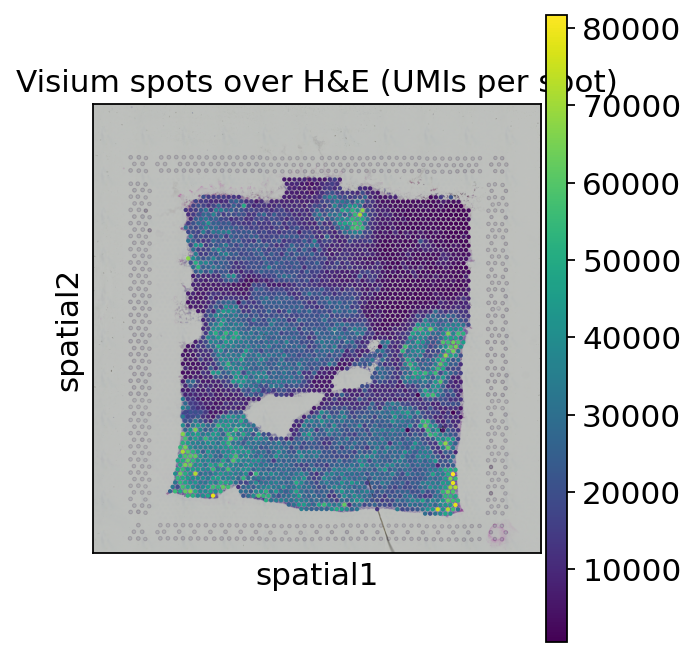

In [17]:
# 2.1 - spots over the H&E image (assignment Part 2, step 1)
spatial.obs["umi_per_spot"] = np.asarray(spatial.X.sum(axis=1)).ravel()
sq.pl.spatial_scatter(spatial, color="umi_per_spot", size=1.3,
                      title="Visium spots over H&E (UMIs per spot)")

## 2.2 · Pipeline and clustering  *(provided)*

In [18]:
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial)
sc.pp.neighbors(spatial)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
print("spatial domains found:", spatial.obs["cluster"].nunique())

/tmp/ipykernel_9465/4117200164.py:2: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], inplace=True)
/tmp/ipykernel_9465/4117200164.py:11: FutureWarning: The argument key_added is deprecated and will be removed in the future. Use `out` instead.
  sc.tl.leiden(spatial, resolution=0.6, key_added="cluster")
/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(*args, **kwargs)


spatial domains found: 9


## 2.3 · Spatial domains on the tissue
**TODO:** draw the clusters back onto the tissue and relate them to tumor, stroma, and immune regions.

/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values


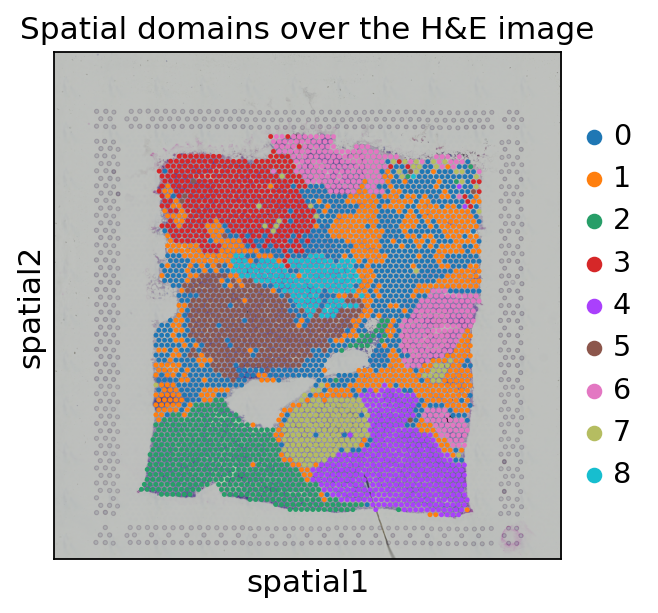

In [19]:
# 2.3 - spatial domains drawn back onto the tissue
sq.pl.spatial_scatter(spatial, color="cluster", size=1.3, title="Spatial domains over the H&E image")

/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in

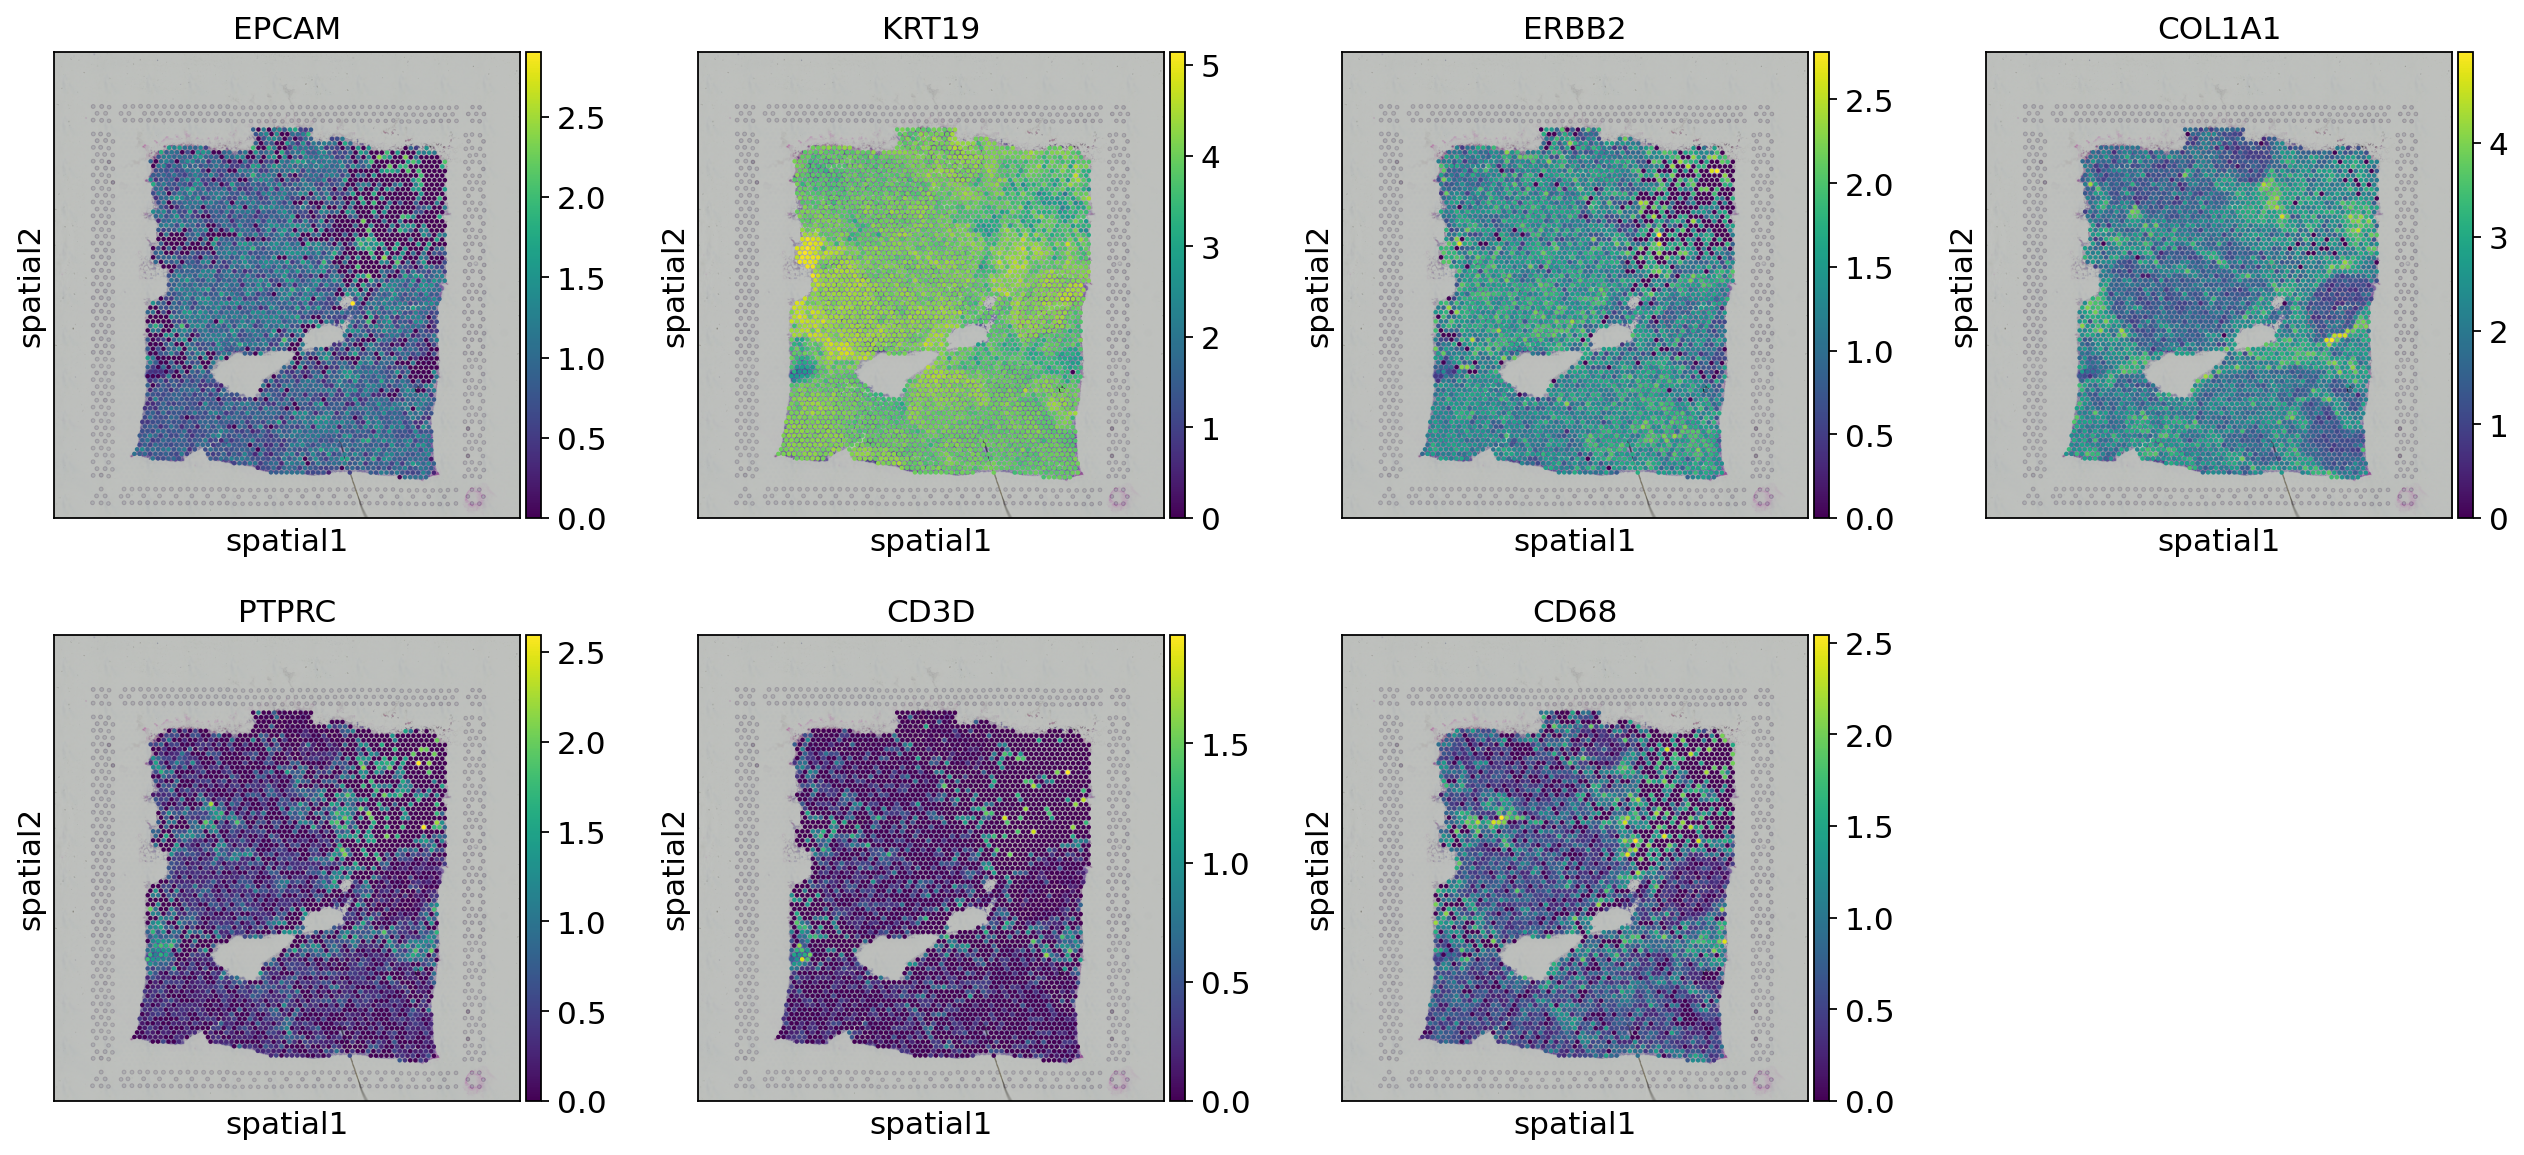

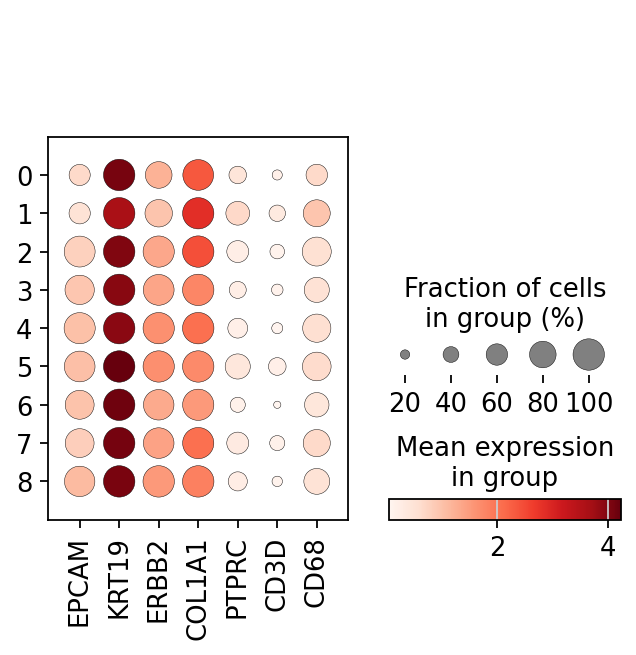

In [20]:
# 2.3 - evidence for naming the domains: canonical markers on tissue + per-domain dot plot
#   tumor/epithelial: EPCAM, ERBB2, KRT19 | stroma: COL1A1 | immune: PTPRC, CD3D, CD68
dom_markers = [g for g in ["EPCAM", "KRT19", "ERBB2", "COL1A1", "PTPRC", "CD3D", "CD68"]
               if g in spatial.var_names]
sq.pl.spatial_scatter(spatial, color=dom_markers, size=1.3, ncols=4)
sc.pl.dotplot(spatial, dom_markers, groupby="cluster")

**TODO (interpretation):** Do the domains line up with recognizable tissue architecture (tumor nests, stroma, immune areas)?

*What to check: the marker dot plot in 2.3 - which domain numbers are high for EPCAM/KRT19/ERBB2 (tumor), COL1A1 (stroma), PTPRC/CD3D/CD68 (immune)?*

*Your answer here.*
Domains 2, 3, 4, 5, 6, 7, and 8 form compact blocks consistent with dense epithelial/tumor nests, while domains 0 and 1 form interleaved strands between them, with relatively more stromal/fibroblast (COL1A1+) and immune (PTPRC/CD68+) content. KRT19 is broadly expressed across the compact tumor blocks (especially domains 2, 3, 4, 5, 6, 7, and 8), suggesting widespread epithelial/carcinoma architecture segmented into transcriptionally distinct tumor sub-regions rather than a single homogeneous mass.

## 2.4 · Spatially variable genes (Moran's I)
The spatial neighbor graph is built for you. **TODO:** compute Moran's I, list the top genes, and plot a few.

In [21]:
sq.gr.spatial_neighbors(spatial)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_9465/2129188737.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(spatial)


Top spatially variable genes by Moran's I:
               I
MGP     0.868504
MALAT1  0.762550
CRISP3  0.726334
CPB1    0.711023
IGHG3   0.703817
IGLC2   0.700306
IGKC    0.680696
ALB     0.667866


/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values


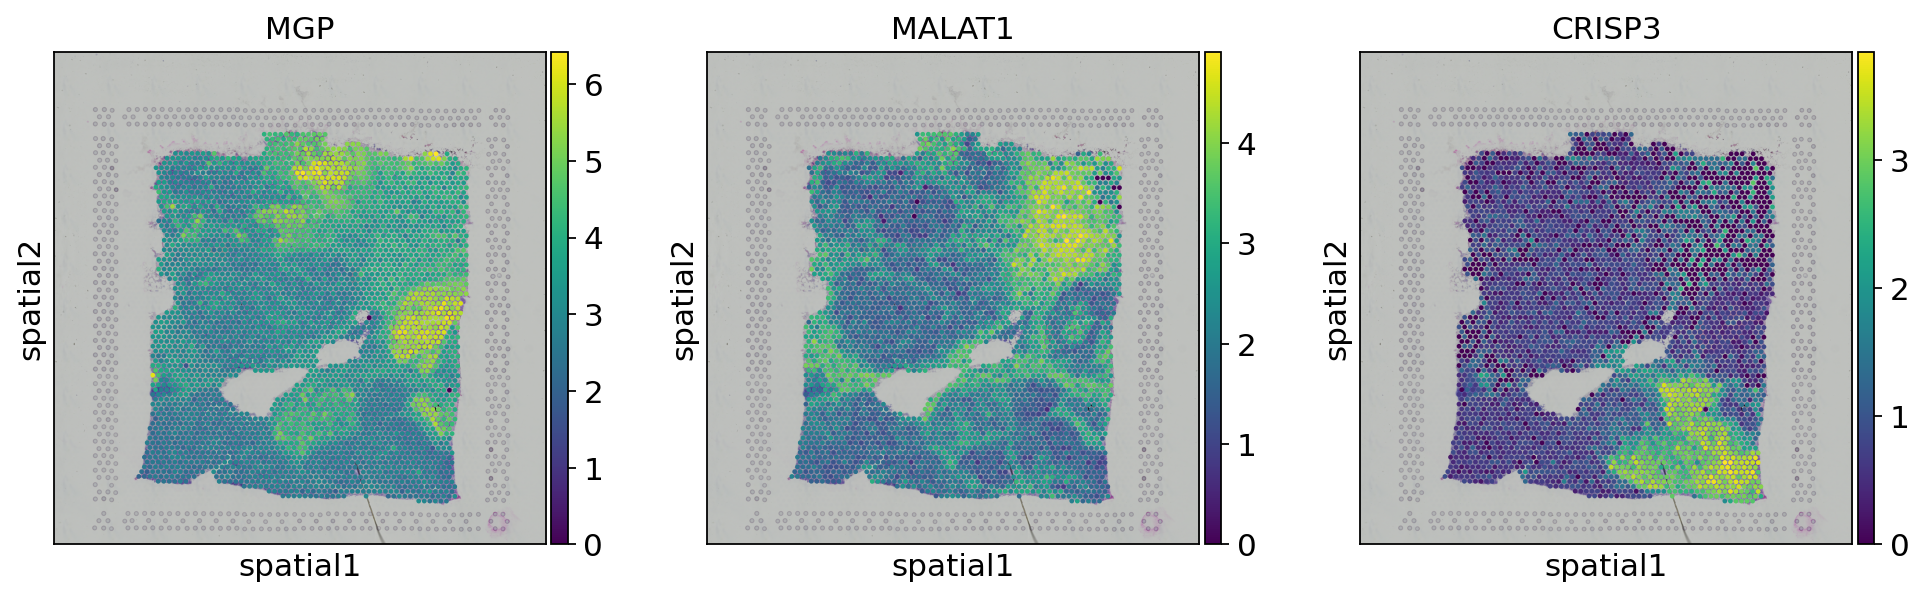

In [22]:
# 2.4 - Moran's I on the highly variable genes, top genes, and the top 3 on tissue
sq.gr.spatial_autocorr(spatial, mode="moran")
top = spatial.uns["moranI"].head(8)
print("Top spatially variable genes by Moran's I:")
print(top[["I"]])
sq.pl.spatial_scatter(spatial, color=spatial.uns["moranI"].head(3).index.tolist(), size=1.3, ncols=3)

## 2.5 · Neighborhood enrichment
**TODO:** compute which domains sit next to each other more than chance, and read off any tumor-immune interface.

nhood_enrichment:   0%|          | 0/1000 [00:00<?, ?perm/s]

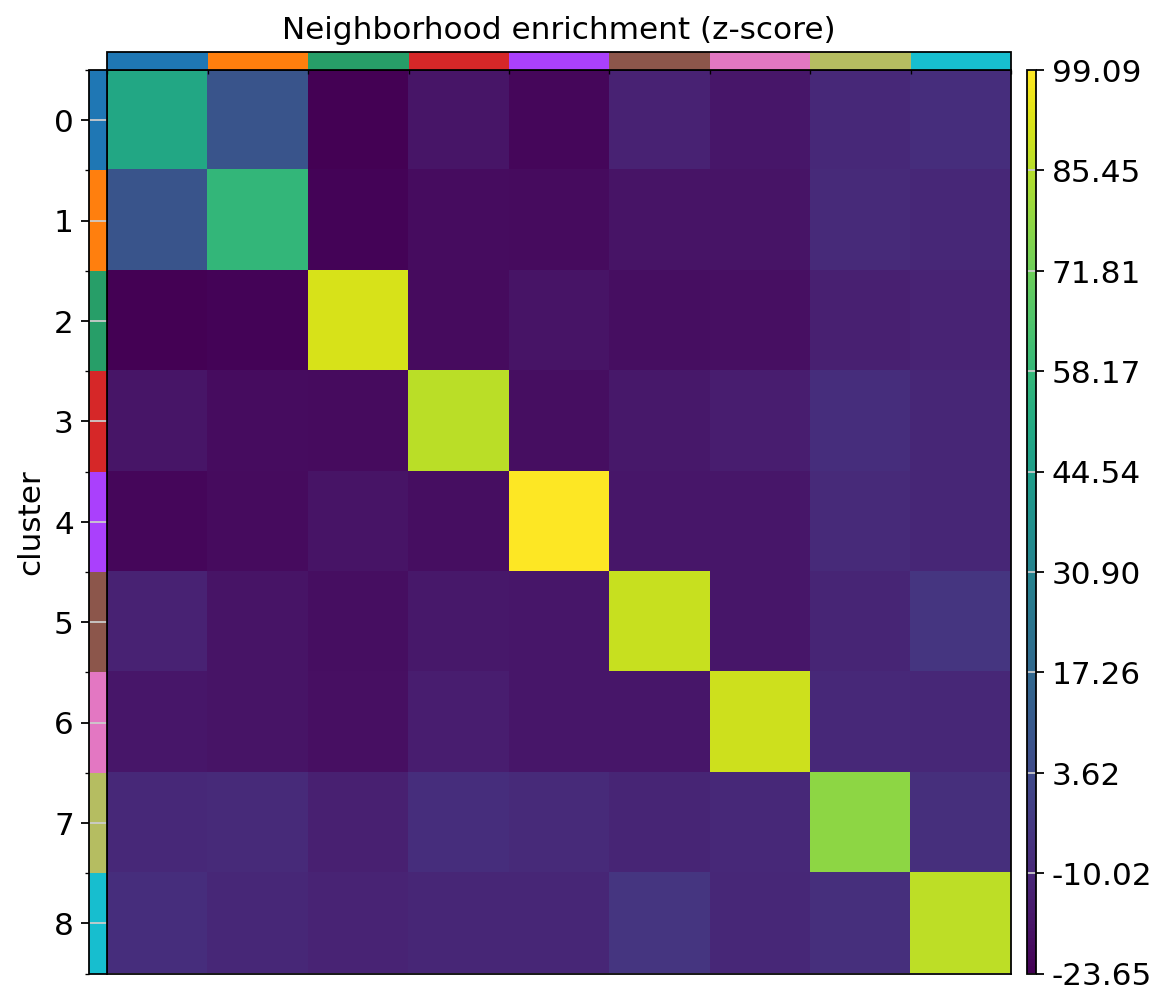

In [23]:
# 2.5 - which domains are neighbors more often than chance (permutation z-scores)
sq.gr.nhood_enrichment(spatial, cluster_key="cluster")
sq.pl.nhood_enrichment(spatial, cluster_key="cluster", title="Neighborhood enrichment (z-score)")

**TODO (interpretation):** Which domains interface more than chance? Is there a tumor-immune boundary?

*What to check: off-diagonal warm squares in the heatmap between a tumor domain and an immune domain (identified from 2.3).*

*Your answer here.*
Every domain is spatially coherent (strong diagonal). The clearest interface is the off-diagonal enrichment between domains 0 and 1 (0↔1), showing that the two stroma-rich interstitial strand domains sit directly alongside each other. A tumor–immune boundary is limited (no single sharp, segregated boundary exists), because immune cells are intermixed within the stromal strands (0 and 1) and the compact tumor blocks do not score above chance against domains 0 and 1 in the neighborhood enrichment heatmap.

## 2.6 · Locate your target in the tissue
**TODO:** color the tissue by the same target gene and describe where it sits.

/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:117: FutureWarning: The argument use_raw is deprecated and will be removed in the future. :attr:`~anndata.AnnData.raw` is deprecated. Keep the data in a layer instead.
  return obs_df(adata, keys=[key], use_raw=True)[key].values
/usr/local/lib/python3.13/dist-packages/squidpy/_compat.py:118: FutureWarning: The argument layer is deprecated and will be removed in the future. Use `use` instead.
  return obs_df(adata, keys=[key], layer=layer)[key].values


cluster
5    1.650
4    1.640
8    1.534
7    1.411
3    1.381
2    1.355
6    1.316
0    1.217
1    0.978
Name: mean ERBB2 per domain, dtype: float32


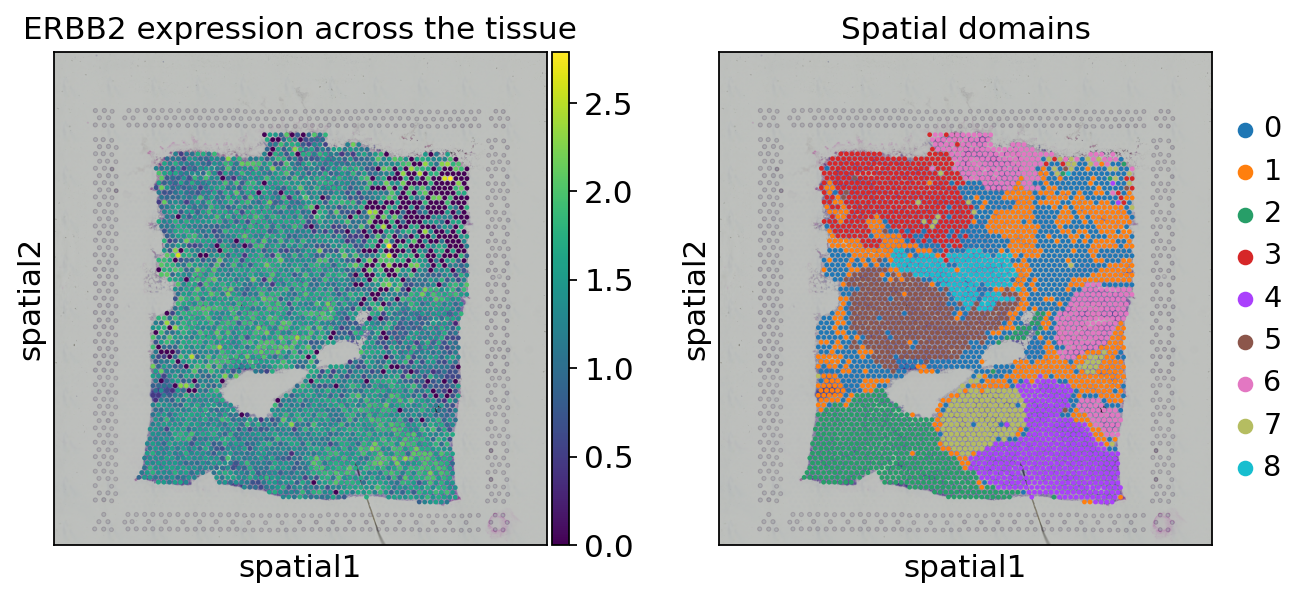

In [24]:
# 2.6 - the same target, now located in the tissue
if TARGET in spatial.raw.var_names:
    sq.pl.spatial_scatter(spatial, color=[TARGET, "cluster"], size=1.3, ncols=2,
                          title=[f"{TARGET} expression across the tissue", "Spatial domains"])
    # which domains carry the target
    print(spatial.obs.assign(t=spatial[:, TARGET].X.toarray().ravel()
                             if hasattr(spatial[:, TARGET].X, "toarray")
                             else np.asarray(spatial[:, TARGET].X).ravel())
          .groupby("cluster", observed=True)["t"].mean().sort_values(ascending=False).round(3)
          .rename(f"mean {TARGET} per domain"))
else:
    print(TARGET, "not in this panel; pick a gene present in spatial.raw.var_names")

**TODO (interpretation):** Where does your target sit: tumor core, invasive margin, or an immune niche?

*What to check: the 2.6 side-by-side plot and the mean-per-domain table - is ERBB2 inside tumor-domain nests, at their edge next to stroma/immune domains, or in immune areas?*

*Your answer here.*
ERBB2 is detected across the whole tissue section, enriched in domains 5, 4, and 8 (mean ≈ 1.6) and lowest in the interstitial stromal strands—domains 1 (0.98) and 0 (1.22). This places it mainly in the tumor core (the dense epithelial tumor blocks) rather than the tumor margin or a distinct immune niche.

---
# PART 3 · Connect it (your report)

Write a 4–5 page report (separate PDF) that ties the two views together:

- Which cell types express your target (Part 1), and where those cells sit in the tumor (Part 2).
- Your integration choice, justified with the scores.
- The spatial context and why it matters clinically (a target at the invasive margin versus shut inside the core).
- The limitations of each analysis: donor count and label resolution (single-cell); spot resolution, panel, and segmentation (spatial).

Then **Kernel → Restart & Run All**, commit this notebook and your report to your biot6900 repo, and post the repo link on Canvas.